# Canadian housing: development-only exploratory analysis

Run `python3 src/data/split_dataset.py` from the project root first. Then run this notebook from top to bottom in the project environment. Only `development_housing.csv` is read; the test partition is reserved for final evaluation.

This is descriptive listing-level analysis, not evidence of causal effects or a representative sample of all Canadian homes. No rows are deleted, no missing values are filled, and no model inputs are created from Price. Existing audit/cleaning decisions predate this split; this holdout is not independent of that earlier investigation. The fixed random split can place nearby or related listings in both partitions. Future spatial, grouped, or temporal evaluation should be considered if suitable identifiers become available.

## 1. Setup and dataset structure

Inspect dimensions, schema, inferred data types, and basic statistics before interpreting plots. Paths work from the project root or notebooks directory. The loaded frame remains unchanged throughout the analysis.

In [2]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 30)

# Find the project without depending on a particular notebook working directory.
PROJECT_ROOT = next(
    folder for folder in [Path.cwd(), *Path.cwd().parents]
    if (folder / "src/data/split_dataset.py").is_file()
)
DEVELOPMENT_PATH = PROJECT_ROOT / "data/processed/development_housing.csv"
df = pd.read_csv(DEVELOPMENT_PATH, encoding="utf-8")
original = df.copy(deep=True)
print(f"Development rows: {len(df):,}; columns: {len(df.columns)}")
print(df.columns.tolist())
display(df.dtypes.rename("dtype").to_frame())
display(df.head())
display(df.describe().T)

Development rows: 32,428; columns: 23
['City', 'Province', 'Latitude', 'Longitude', 'Price', 'Bedrooms', 'Bathrooms', 'Acreage', 'Property Type', 'Square Footage', 'Garage', 'Parking', 'Basement', 'Exterior', 'Fireplace', 'Heating', 'Flooring', 'Roof', 'Waterfront', 'Sewer', 'Pool', 'Garden', 'Balcony']


,dtype
City,str
Province,str
Latitude,float64
Longitude,float64
Price,float64
Bedrooms,float64
Bathrooms,float64
Acreage,float64
Property Type,str
Square Footage,float64


,City,Province,Latitude,Longitude,Price,Bedrooms,Bathrooms,Acreage,Property Type,Square Footage,Garage,Parking,Basement,Exterior,Fireplace,Heating,Flooring,Roof,Waterfront,Sewer,Pool,Garden,Balcony
0,Mission,BC,49.161331,-122.310936,789900.0,4.0,4.0,0.00,Condo/Townhome,1744.0,Yes,No,NaN,NaN,Yes,forced air,NaN,NaN,No,municipal,No,No,No
1,Burnaby,BC,49.208350,-122.960549,1349900.0,3.0,3.0,0.00,Townhome,1587.0,Yes,No,NaN,NaN,No,radiant,NaN,NaN,No,none,No,No,No
2,Bedford,NS,44.708118,-63.721050,821900.0,4.0,3.0,0.13,Single Family,2379.0,Yes,No,NaN,Vinyl,Yes,NaN,wood,NaN,No,municipal,No,No,No
3,Abbotsford,BC,49.033646,-122.297044,1200000.0,3.0,3.0,0.22,Single Family,1900.0,Yes,Yes,NaN,NaN,No,forced air,NaN,NaN,No,none,No,No,No
4,Ancaster,ON,43.224230,-79.991676,1325000.0,4.0,4.0,0.00,Single Family,2758.0,Yes,No,Finished,Brick,Yes,forced air,NaN,NaN,No,municipal,No,No,No


,count,mean,std,min,25%,50%,75%,max
Latitude,32428.0,4.887139e+01,2.613203e+00,42.045940,48.451386,49.201390,4.973115e+01,6.528149e+01
Longitude,32428.0,-1.070524e+02,2.277947e+01,-135.856018,-122.941532,-120.827735,-1.020718e+02,-5.266860e+01
Price,32428.0,1.134304e+06,1.528628e+06,50000.000000,439900.000000,724900.000000,1.299000e+06,5.880000e+07
Bedrooms,32428.0,3.225422e+00,1.648127e+00,0.000000,2.000000,3.000000,4.000000e+00,3.700000e+01
Bathrooms,32428.0,2.552455e+00,1.453654e+00,0.000000,2.000000,2.000000,3.000000e+00,2.600000e+01
Acreage,32428.0,2.520779e+00,9.402878e+01,0.000000,0.000000,0.000000,1.800000e-01,8.600000e+03
Square Footage,32428.0,1.824541e+03,2.072440e+03,150.000000,975.000000,1440.000000,2.249000e+03,2.900340e+05


**Interpretation after running:**

- What pattern is visible, and how many listings support it?
- What uncertainty, missingness, or confounding could explain it?
- What should be investigated using development data or cross-validation?

_Write observations here; no findings are assumed in advance._

## 2. Missing values and patterns

Report counts and percentages without imputing. A fixed-seed sample of the missingness matrix makes co-missingness visible without plotting every listing. Missing attributes are unknown, not necessarily absent.

,count,percent
Roof,26059,80.359566
Basement,22597,69.683607
Flooring,21735,67.025410
Exterior,20614,63.568521
Heating,4927,15.193660
City,0,0.000000
Garden,0,0.000000
Pool,0,0.000000
Sewer,0,0.000000
Waterfront,0,0.000000


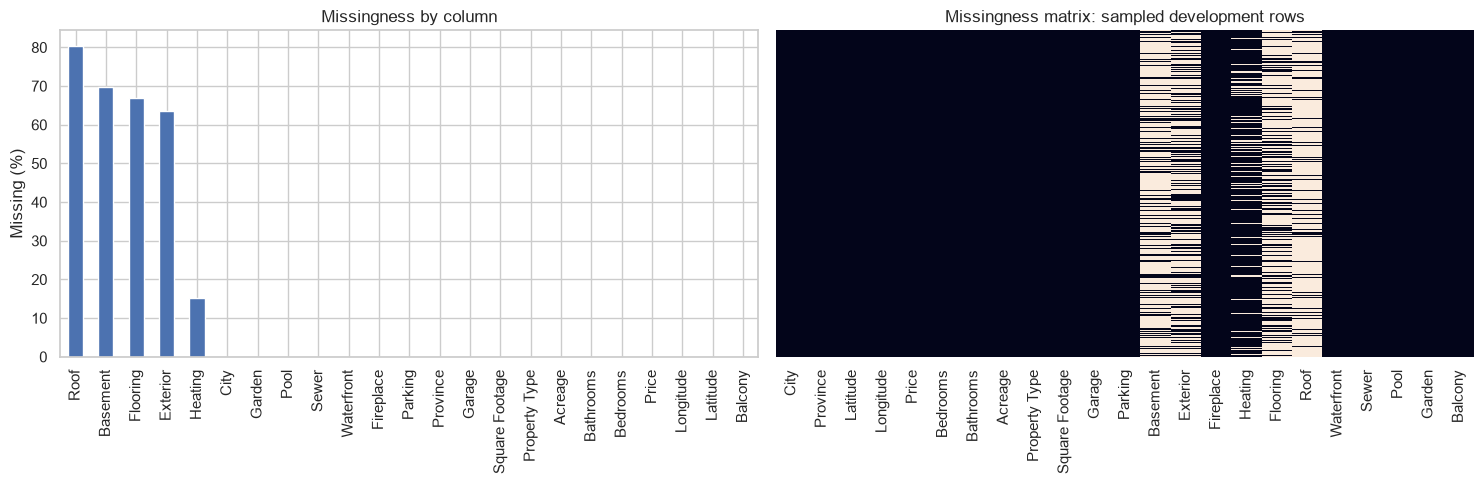

,City,Province,Latitude,Longitude,Price,Bedrooms,Bathrooms,Acreage,Property Type,Square Footage,Garage,Parking,Basement,Exterior,Fireplace,Heating,Flooring,Roof,Waterfront,Sewer,Pool,Garden,Balcony
Property Type,,,,,,,,,,,,,,,,,,,,,,,
Condo,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,100.00,80.92,0.0,13.86,80.03,100.00,0.0,0.0,0.0,0.0,0.0
Condo/Townhome,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,100.00,81.63,0.0,11.14,79.25,100.00,0.0,0.0,0.0,0.0,0.0
Duplex,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,58.71,91.36,0.0,5.62,66.80,55.83,0.0,0.0,0.0,0.0,0.0
Manufactured Home,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,100.00,94.25,0.0,12.64,82.18,69.54,0.0,0.0,0.0,0.0,0.0
Mobile Home,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,100.00,30.83,0.0,10.53,68.42,1.50,0.0,0.0,0.0,0.0,0.0
MultiFamily,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,43.63,39.71,0.0,17.16,96.08,93.63,0.0,0.0,0.0,0.0,0.0
Single Family,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,50.07,49.65,0.0,16.98,57.78,70.69,0.0,0.0,0.0,0.0,0.0
Townhome,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,100.00,99.01,0.0,10.11,83.67,81.17,0.0,0.0,0.0,0.0,0.0


In [3]:
missing = pd.DataFrame({"count": df.isna().sum(), "percent": df.isna().mean() * 100}).sort_values("percent", ascending=False)
display(missing)
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
missing["percent"].plot.bar(ax=axes[0], ylabel="Missing (%)", title="Missingness by column")
sample = df.sample(n=min(500, len(df)), random_state=42)
sns.heatmap(sample.isna(), cbar=False, yticklabels=False, ax=axes[1])
axes[1].set_title("Missingness matrix: sampled development rows")
plt.tight_layout()
plt.show()
# Property type can explain why some building attributes are rarely reported.
display(df.isna().groupby(df["Property Type"], dropna=False).mean().mul(100).round(2))

**Interpretation after running:**

- What pattern is visible, and how many listings support it?
- What uncertainty, missingness, or confounding could explain it?
- What should be investigated using development data or cross-validation?

_Write observations here; no findings are assumed in advance._

## 3. Price distribution and skewness

Compare raw prices with log10 prices for positive values. Logarithms here are visualization aids, not engineered predictors. Report any nonpositive values excluded from the logarithmic panel.

Raw Price skewness: 8.332289401327062
Nonpositive prices excluded from log view: 0


count    3.242800e+04
mean     1.134304e+06
std      1.528628e+06
min      5.000000e+04
1%       8.000000e+04
25%      4.399000e+05
50%      7.249000e+05
75%      1.299000e+06
95%      3.323185e+06
99%      6.935040e+06
max      5.880000e+07
Name: Price, dtype: float64

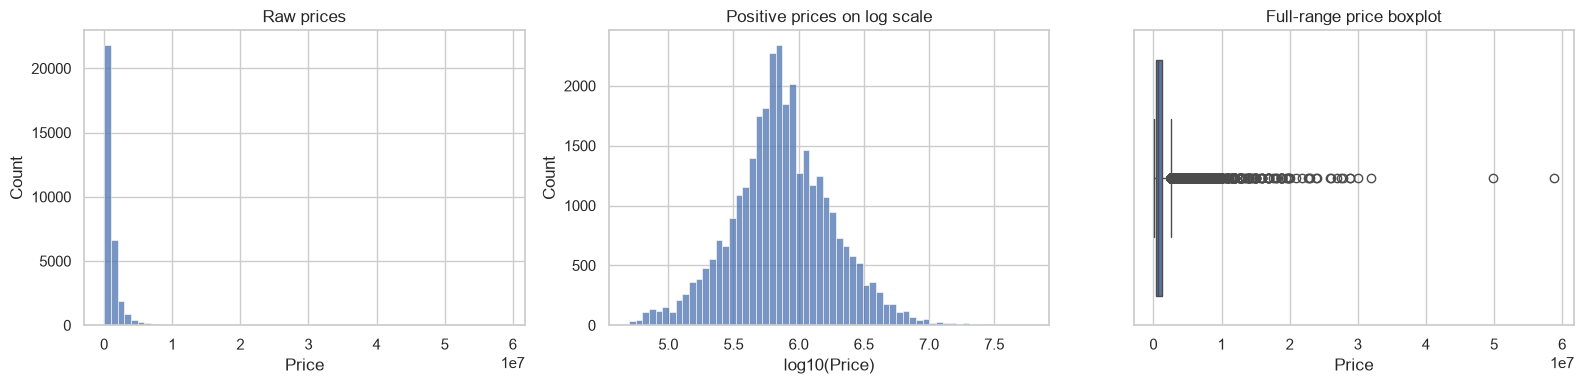

In [4]:
price = df["Price"]
positive_price = price[price > 0]
print("Raw Price skewness:", price.skew())
print("Nonpositive prices excluded from log view:", price.le(0).sum())
display(price.describe(percentiles=[.01, .25, .5, .75, .95, .99]))
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
sns.histplot(price, bins=60, ax=axes[0])
sns.histplot(np.log10(positive_price), bins=60, ax=axes[1])
axes[1].set_xlabel("log10(Price)")
sns.boxplot(x=price, ax=axes[2])
axes[0].set_title("Raw prices")
axes[1].set_title("Positive prices on log scale")
axes[2].set_title("Full-range price boxplot")
plt.tight_layout()
plt.show()

**Interpretation after running:**

- What pattern is visible, and how many listings support it?
- What uncertainty, missingness, or confounding could explain it?
- What should be investigated using development data or cross-validation?

_Write observations here; no findings are assumed in advance._

## 4. Price versus property dimensions

Scatter plots show associations with square footage, bedrooms, bathrooms, and acreage. Transparency reveals overlapping observations. Separate median/count tables help interpret discrete room counts. Plotting omits missing pairs only; it does not change the data.

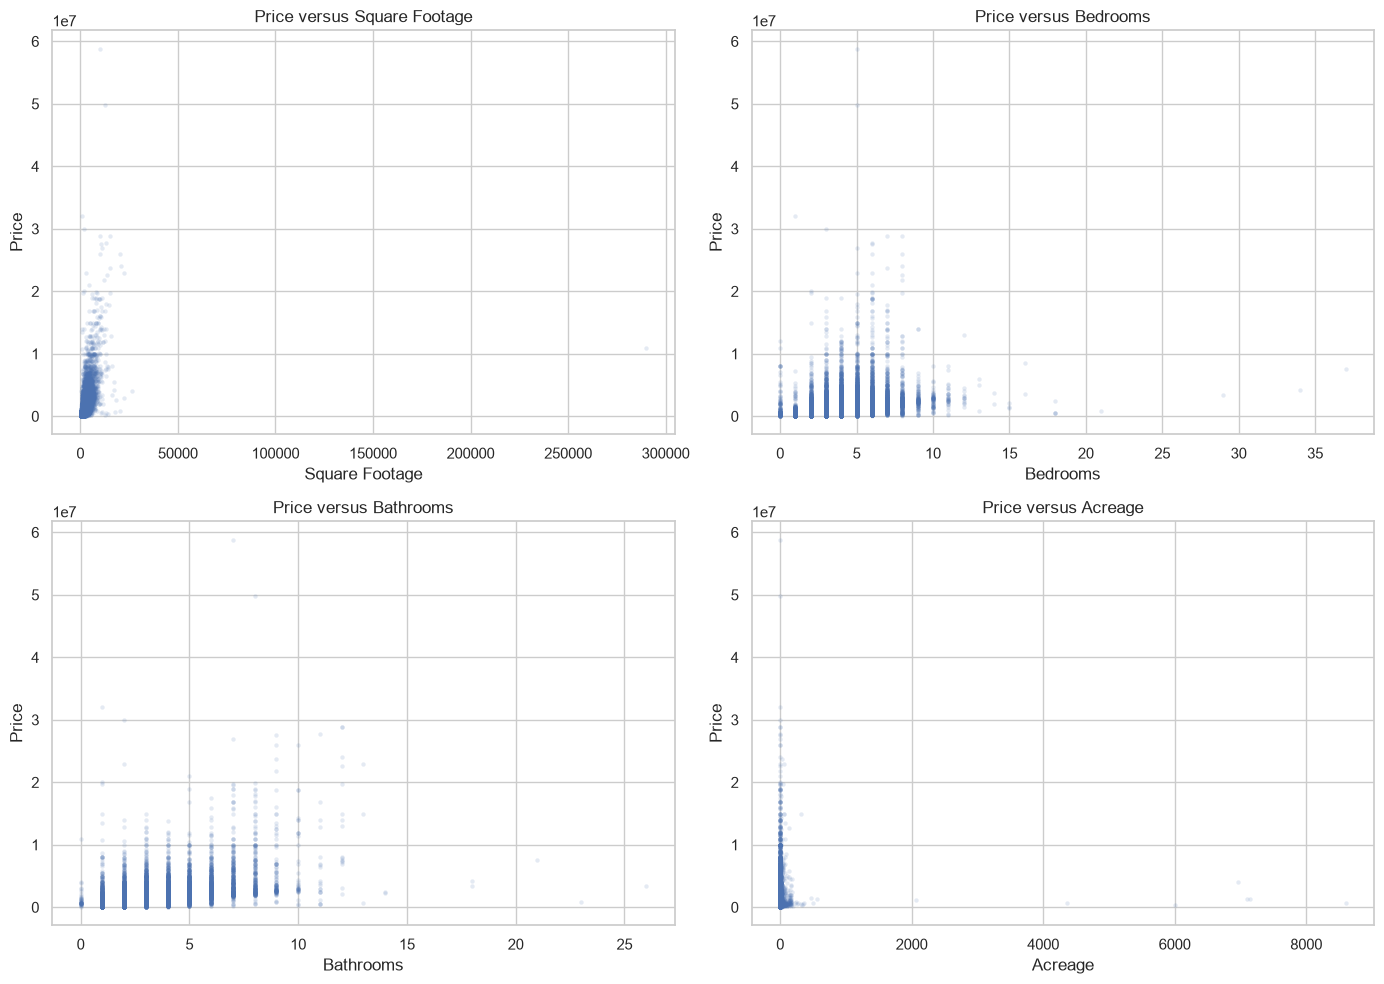

,count,median,mean
Bedrooms,,,
0.0,258,465000.0,1.031553e+06
1.0,3165,525000.0,5.571666e+05
2.0,8387,628000.0,7.333019e+05
3.0,8799,679900.0,9.175599e+05
4.0,5878,899999.0,1.276891e+06
5.0,3278,1269900.0,1.774866e+06
6.0,1454,1788444.0,2.501529e+06
7.0,630,2105000.0,2.932442e+06
8.0,334,2249000.0,3.068722e+06


,count,median,mean
Bathrooms,,,
0.0,47,748000.0,1.313593e+06
1.0,7134,439000.0,5.395862e+05
2.0,11561,648800.0,8.082580e+05
3.0,7503,899000.0,1.188275e+06
4.0,3793,1289000.0,1.576882e+06
5.0,1016,2064000.0,2.561706e+06
6.0,645,2666000.0,3.245122e+06
7.0,340,3199500.0,4.607096e+06
8.0,205,3598000.0,5.567376e+06


In [5]:
dimensions = ["Square Footage", "Bedrooms", "Bathrooms", "Acreage"]
fig, axes = plt.subplots(2, 2, figsize=(14, 10))
for column, ax in zip(dimensions, axes.flat):
    sns.scatterplot(data=df, x=column, y="Price", alpha=.15, s=10, linewidth=0, ax=ax)
    ax.set_title(f"Price versus {column}")
plt.tight_layout()
plt.show()
for column in ["Bedrooms", "Bathrooms"]:
    display(df.groupby(column)["Price"].agg(["count", "median", "mean"]))

**Interpretation after running:**

- What pattern is visible, and how many listings support it?
- What uncertainty, missingness, or confounding could explain it?
- What should be investigated using development data or cross-validation?

_Write observations here; no findings are assumed in advance._

## 5. Prices by province, city, and property type

Compare counts, median, quartiles, and mean prices. Cities are identified jointly with province because place names repeat. City plots use the 20 most frequent city/province pairs for readability; complete tables remain available. Differences can reflect property mix and listing coverage rather than location alone.

,count,median,mean,q25,q75
Province,,,,,
NT,9,144900.0,2.550889e+05,118000.0,349900.0
SK,2893,269000.0,3.472357e+05,165000.0,449000.0
NL,1099,299900.0,3.676332e+05,189900.0,449000.0
MB,51,339900.0,3.596173e+05,204950.0,464940.0
NB,1544,349900.0,4.193139e+05,229900.0,499900.0
PE,598,420000.0,5.009547e+05,324925.0,599000.0
NS,1800,490800.0,5.638458e+05,314000.0,697025.0
AB,3230,519900.0,6.494528e+05,335000.0,748402.5
YT,32,599850.0,6.656519e+05,444900.0,734000.0


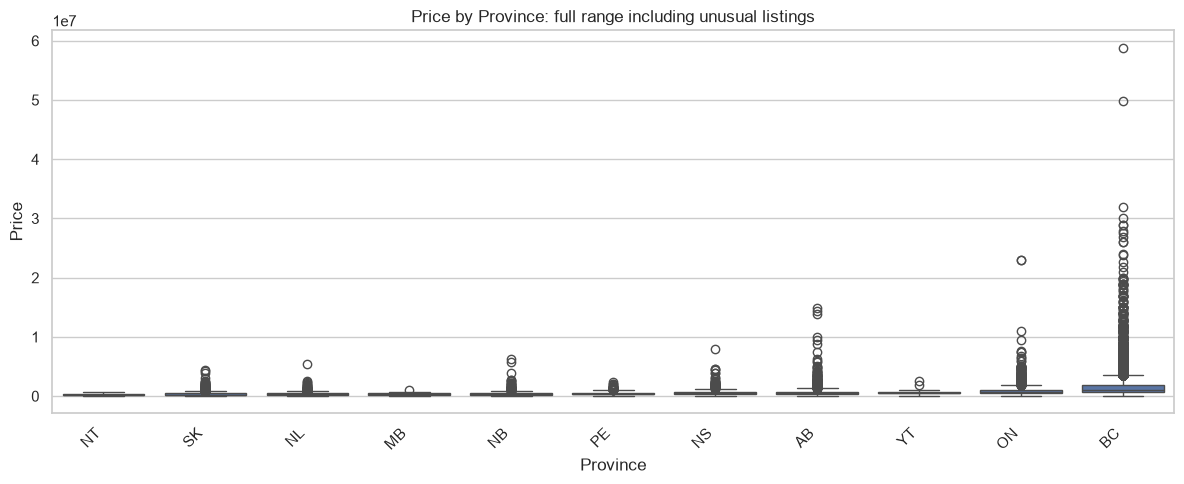

,count,median,mean,q25,q75
Property Type,,,,,
Mobile Home,133,135000.0,1.628346e+05,90000.0,189900.0
Manufactured Home,174,329900.0,4.263899e+05,249900.0,439375.0
Condo,9436,639000.0,7.819706e+05,479900.0,849900.0
Single Family,18855,775900.0,1.334542e+06,379900.0,1639900.0
Condo/Townhome,1176,799999.0,8.700335e+05,529900.0,1089925.0
Townhome,1721,947500.0,1.053701e+06,739900.0,1208000.0
MultiFamily,204,1087500.0,1.682824e+06,727400.0,2162750.0
Duplex,729,1329900.0,1.325162e+06,619900.0,1799900.0


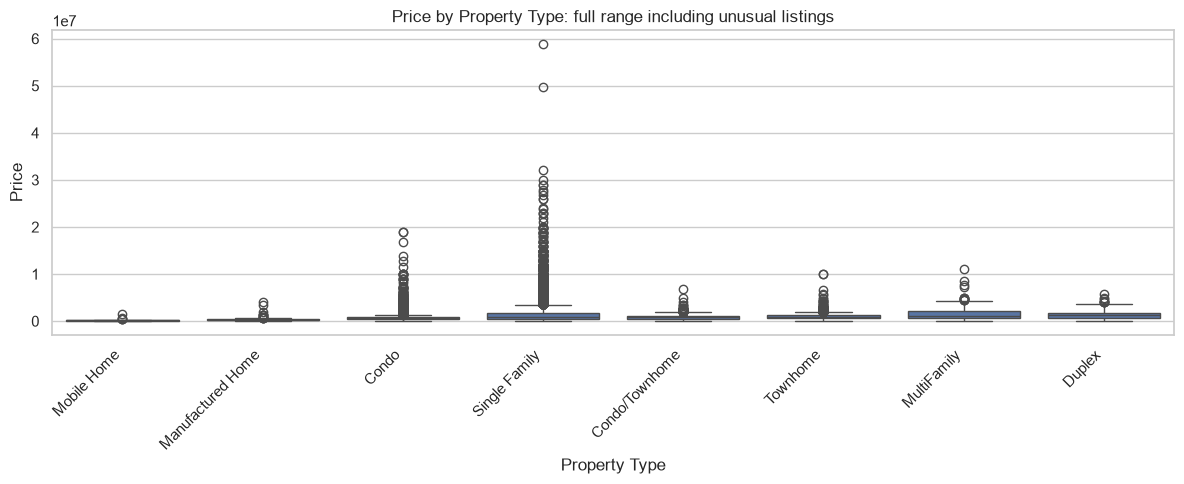

count     median          mean
Province City                                       
BC       Vancouver     3117  1528000.0  2.284352e+06
         Surrey        2696   999000.0  1.430989e+06
AB       Calgary       1269   595000.0  7.152157e+05
BC       Richmond      1103  1168000.0  1.675062e+06
         Burnaby       1093   918000.0  1.334338e+06
...                     ...        ...           ...
NS       Caledonia        1   319900.0  3.199000e+05
         Bucklaw          1   109500.0  1.095000e+05
         Brule Point      1   364500.0  3.645000e+05
         Brule            1   540000.0  5.400000e+05
YT       Yukon Wide       1   459000.0  4.590000e+05

[2851 rows x 3 columns]

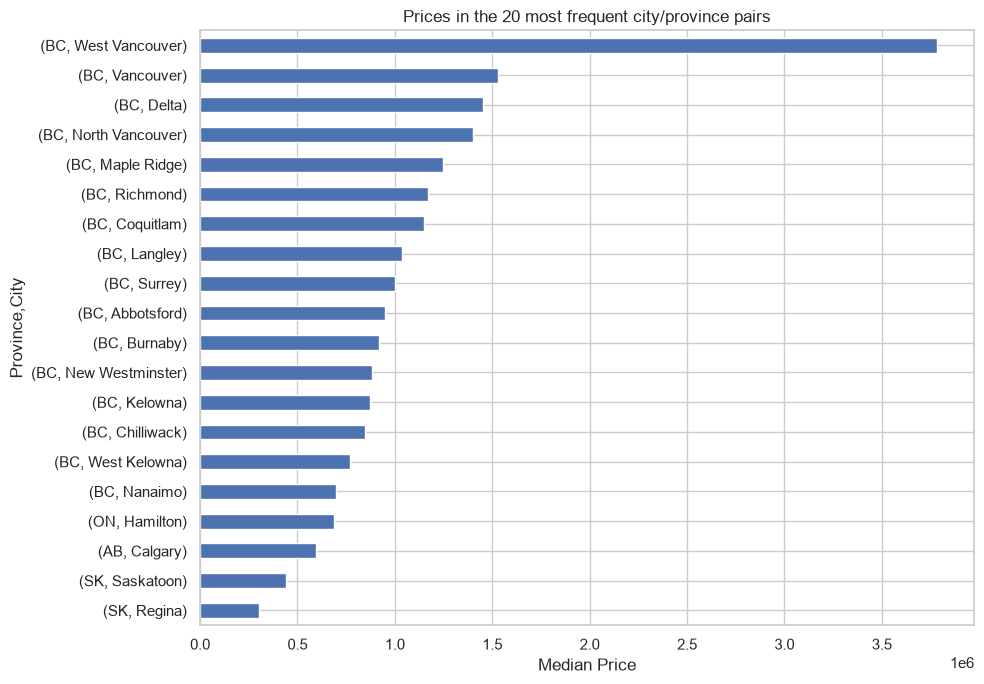

In [6]:
for column in ["Province", "Property Type"]:
    summary = df.groupby(column, dropna=False)["Price"].agg(
        count="count", median="median", mean="mean",
        q25=lambda s: s.quantile(.25), q75=lambda s: s.quantile(.75))
    display(summary.sort_values("median"))
    plt.figure(figsize=(12, 5))
    sns.boxplot(data=df, x=column, y="Price", order=summary.sort_values("median").index)
    plt.xticks(rotation=45, ha="right")
    plt.title(f"Price by {column}: full range including unusual listings")
    plt.tight_layout()
    plt.show()
city_prices = df.groupby(["Province", "City"], dropna=False)["Price"].agg(["count", "median", "mean"])
display(city_prices.sort_values("count", ascending=False))
common_cities = city_prices.nlargest(20, "count").sort_values("median")
common_cities["median"].rename(index=lambda x: x).plot.barh(figsize=(10, 7))
plt.xlabel("Median Price")
plt.title("Prices in the 20 most frequent city/province pairs")
plt.tight_layout()
plt.show()

**Interpretation after running:**

- What pattern is visible, and how many listings support it?
- What uncertainty, missingness, or confounding could explain it?
- What should be investigated using development data or cross-validation?

_Write observations here; no findings are assumed in advance._

## 6. Pearson and Spearman correlations

Pearson summarizes linear associations; Spearman summarizes monotonic rank associations and is less sensitive to extreme magnitudes. Both use available pairs, so pair counts are reported. Price appears only as an analysis target. Correlations are not causal effects; coordinates and room counts can be confounded by province and property type.

,Latitude,Longitude,Price,Bedrooms,Bathrooms,Acreage,Square Footage
Latitude,1.000000,-0.605803,-0.004910,0.010692,0.024237,0.009651,-0.046051
Longitude,-0.605803,1.000000,-0.251341,0.017847,-0.125009,0.001276,-0.006764
Price,-0.004910,-0.251341,1.000000,0.356392,0.521720,0.007453,0.429750
Bedrooms,0.010692,0.017847,0.356392,1.000000,0.747438,0.007372,0.426490
Bathrooms,0.024237,-0.125009,0.521720,0.747438,1.000000,-0.000363,0.492717
Acreage,0.009651,0.001276,0.007453,0.007372,-0.000363,1.000000,0.004168
Square Footage,-0.046051,-0.006764,0.429750,0.426490,0.492717,0.004168,1.000000


,Latitude,Longitude,Price,Bedrooms,Bathrooms,Acreage,Square Footage
Latitude,1.000000,-0.269180,-0.071447,-0.025232,0.018757,0.048967,-0.107117
Longitude,-0.269180,1.000000,-0.537202,0.106483,-0.079319,0.156210,0.045211
Price,-0.071447,-0.537202,1.000000,0.410476,0.577341,0.159837,0.582857
Bedrooms,-0.025232,0.106483,0.410476,1.000000,0.720564,0.498192,0.790687
Bathrooms,0.018757,-0.079319,0.577341,0.720564,1.000000,0.273601,0.783643
Acreage,0.048967,0.156210,0.159837,0.498192,0.273601,1.000000,0.470344
Square Footage,-0.107117,0.045211,0.582857,0.790687,0.783643,0.470344,1.000000


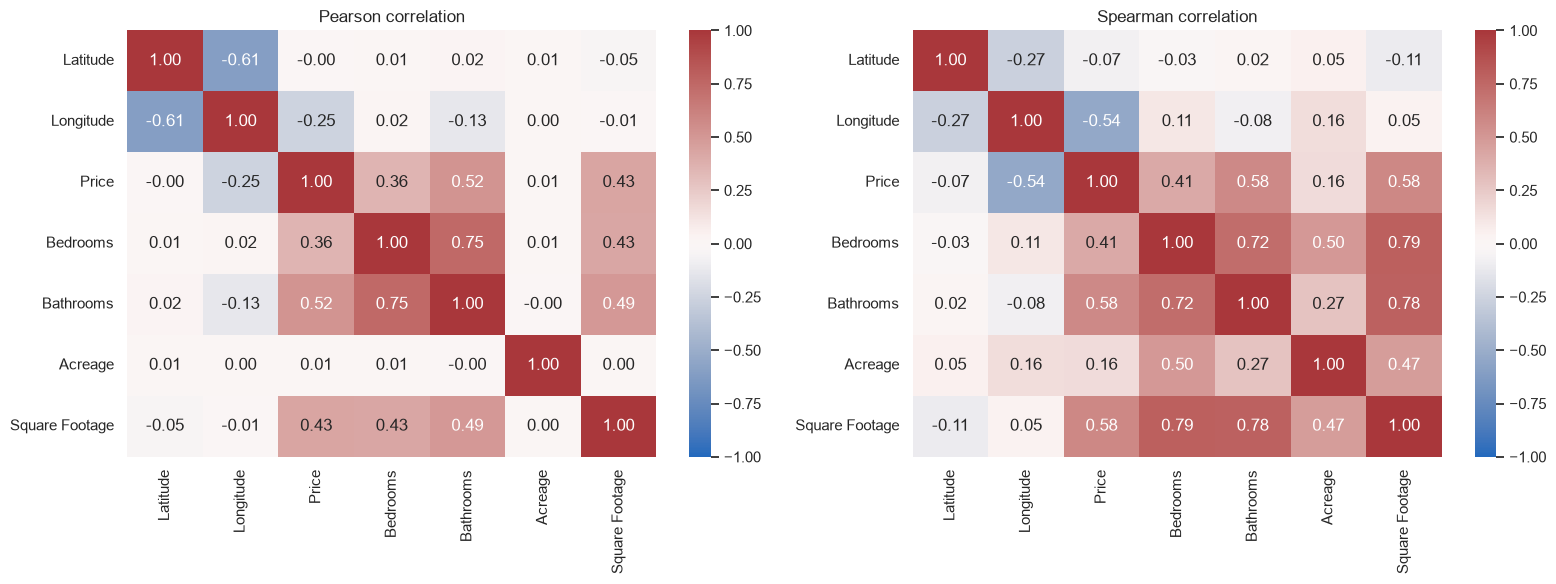

,Latitude,Longitude,Price,Bedrooms,Bathrooms,Acreage,Square Footage
Pairwise available rows,,,,,,,
Latitude,32428,32428,32428,32428,32428,32428,32428
Longitude,32428,32428,32428,32428,32428,32428,32428
Price,32428,32428,32428,32428,32428,32428,32428
Bedrooms,32428,32428,32428,32428,32428,32428,32428
Bathrooms,32428,32428,32428,32428,32428,32428,32428
Acreage,32428,32428,32428,32428,32428,32428,32428
Square Footage,32428,32428,32428,32428,32428,32428,32428


In [7]:
numeric = df.select_dtypes(include="number")
fig, axes = plt.subplots(1, 2, figsize=(16, 6))
for method, ax in zip(["pearson", "spearman"], axes):
    correlation = numeric.corr(method=method)
    display(correlation)
    sns.heatmap(correlation, vmin=-1, vmax=1, cmap="vlag", annot=True, fmt=".2f", ax=ax)
    ax.set_title(f"{method.title()} correlation")
plt.tight_layout()
plt.show()
available = numeric.notna().astype(int)
display((available.T @ available).rename_axis("Pairwise available rows"))

**Interpretation after running:**

- What pattern is visible, and how many listings support it?
- What uncertainty, missingness, or confounding could explain it?
- What should be investigated using development data or cross-validation?

_Write observations here; no findings are assumed in advance._

## 7. Categories and rare groups

Report counts including missing values for every categorical field. For exploration only, define rare as less than 1% of development rows; this is a display convention, not an exclusion or encoding rule. No categories are combined. Small groups have less stable price summaries.


City: 2752 observed categories (including missing)


,count,percent
City,,
Vancouver,3117,9.612064
Surrey,2696,8.313803
Calgary,1269,3.913285
Richmond,1105,3.407549
Burnaby,1093,3.370544
...,...,...
Denman Island,1,0.003084
Saltcoats Rm No. 213,1,0.003084
Denzil,1,0.003084


,count,percent
Rare category,,
Kitchener,306,0.943629
Victoria,298,0.918959
Mission,270,0.832614
Langford,264,0.814111
White Rock,229,0.706180
...,...,...
Denman Island,1,0.003084
Saltcoats Rm No. 213,1,0.003084
Denzil,1,0.003084


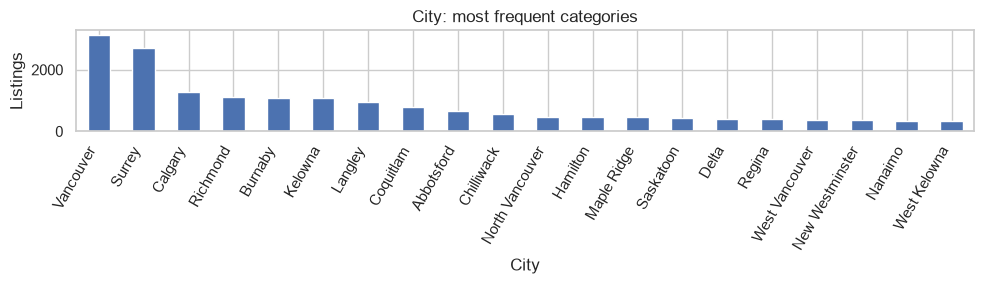


Province: 11 observed categories (including missing)


,count,percent
Province,,
BC,18268,56.334032
AB,3230,9.960528
ON,2904,8.955224
SK,2893,8.921303
NS,1800,5.550759
NB,1544,4.761317
NL,1099,3.389047
PE,598,1.844085
MB,51,0.157271


,count,percent
Rare category,,
MB,51,0.157271
YT,32,0.098680
NT,9,0.027754


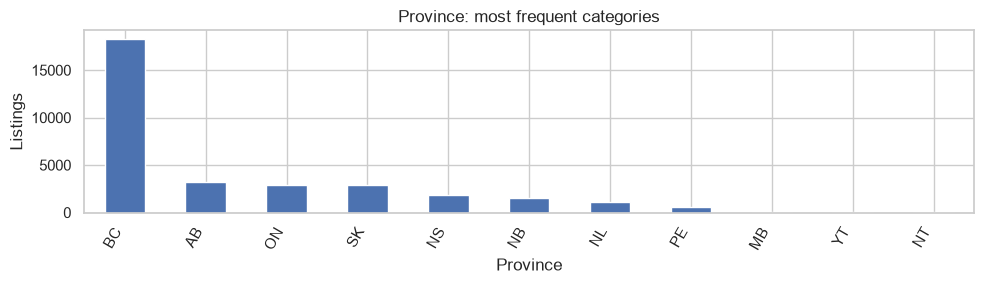


Property Type: 8 observed categories (including missing)


,count,percent
Property Type,,
Single Family,18855,58.144196
Condo,9436,29.098310
Townhome,1721,5.307142
Condo/Townhome,1176,3.626496
Duplex,729,2.248057
MultiFamily,204,0.629086
Manufactured Home,174,0.536573
Mobile Home,133,0.410139


,count,percent
Rare category,,
MultiFamily,204,0.629086
Manufactured Home,174,0.536573
Mobile Home,133,0.410139


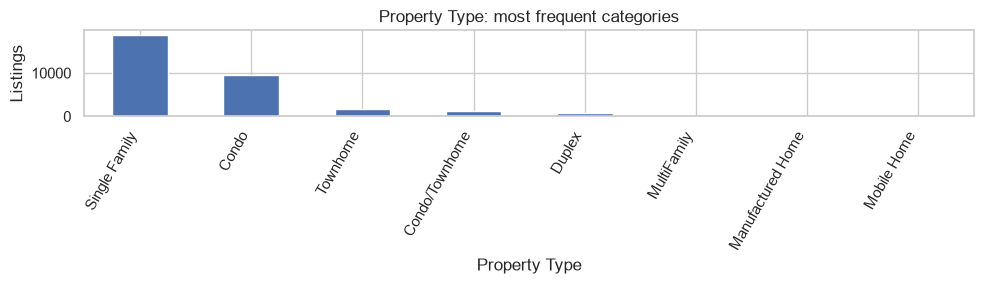


Garage: 2 observed categories (including missing)


,count,percent
Garage,,
Yes,23249,71.694215
No,9179,28.305785


,count,percent
Rare category,,


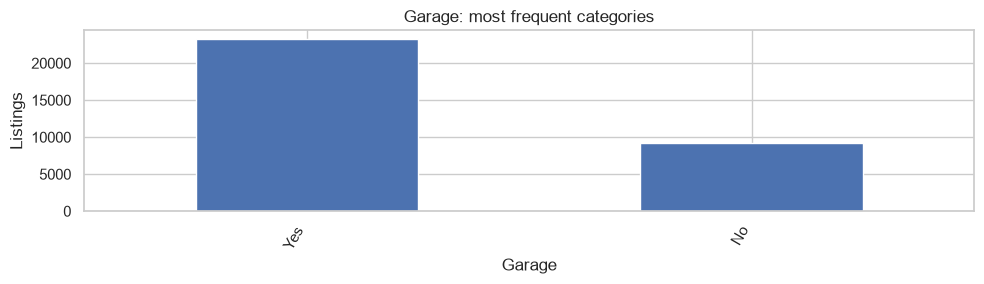


Parking: 2 observed categories (including missing)


,count,percent
Parking,,
No,18824,58.0486
Yes,13604,41.9514


,count,percent
Rare category,,


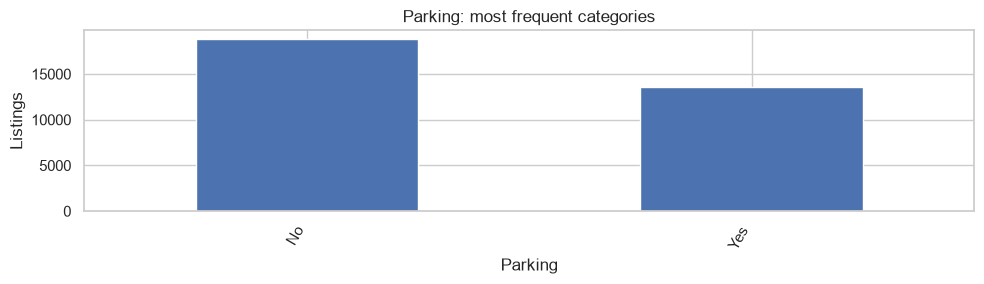


Basement: 4 observed categories (including missing)


,count,percent
Basement,,
NaN,22597,69.683607
Finished,7291,22.483656
No basement,1906,5.877637
Partial,634,1.955101


,count,percent
Rare category,,


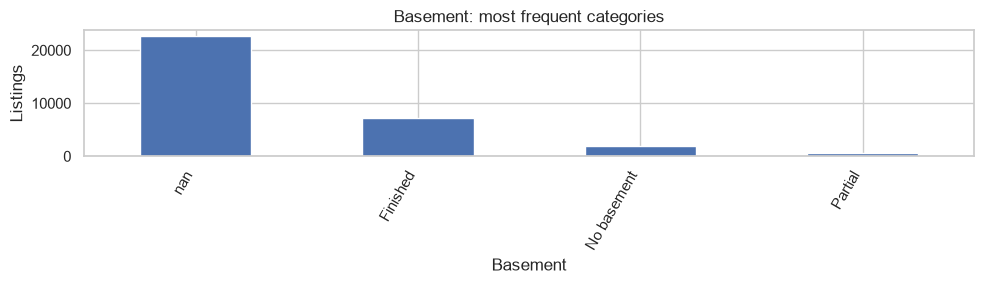


Exterior: 7 observed categories (including missing)


,count,percent
Exterior,,
NaN,20614,63.568521
Vinyl,5258,16.214383
Brick,2514,7.752560
Concrete,1541,4.752066
Wood,1294,3.990379
Metal,775,2.389910
Composite,432,1.332182


,count,percent
Rare category,,


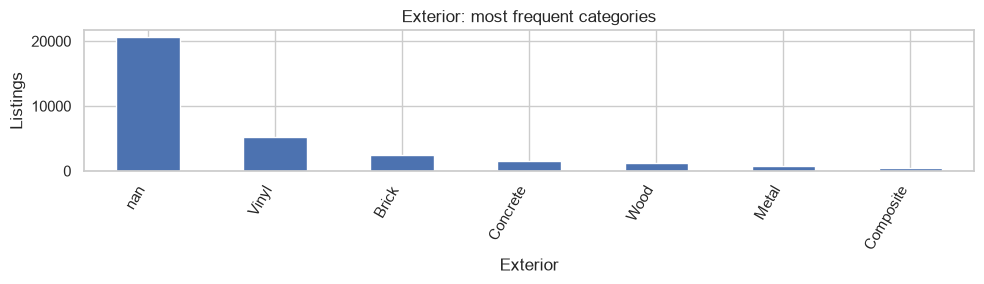


Fireplace: 2 observed categories (including missing)


,count,percent
Fireplace,,
No,18741,57.792648
Yes,13687,42.207352


,count,percent
Rare category,,


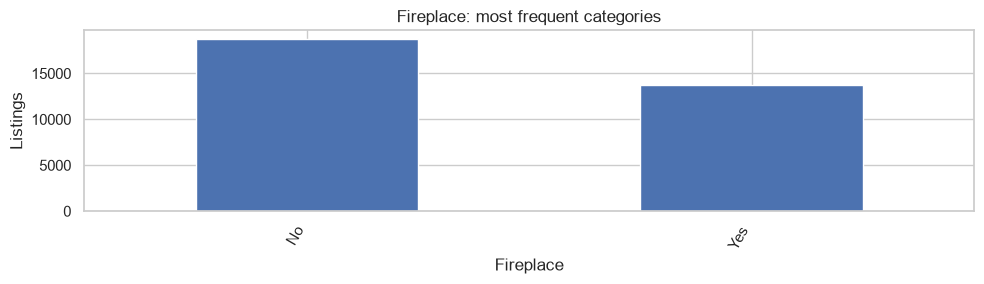


Heating: 10 observed categories (including missing)


,count,percent
Heating,,
forced air,14825,45.716665
radiant,7015,21.632540
NaN,4927,15.193660
heat pump,3187,9.827926
boiler,1897,5.849883
alt heat,343,1.057728
fireplace,121,0.373134
other,46,0.141853
no heat,38,0.117183


,count,percent
Rare category,,
fireplace,121,0.373134
other,46,0.141853
no heat,38,0.117183
space heat,29,0.089429


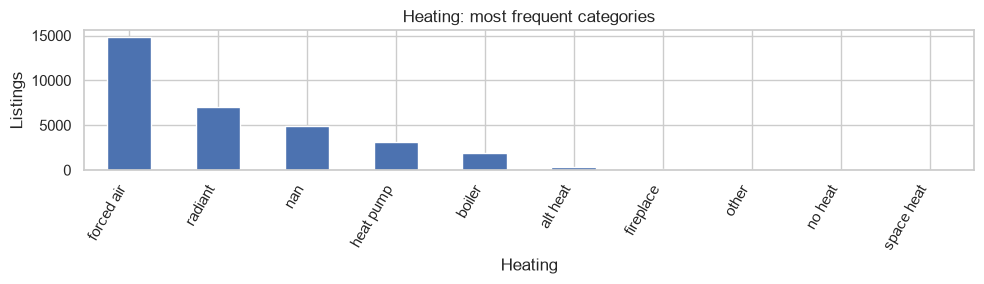


Flooring: 8 observed categories (including missing)


,count,percent
Flooring,,
NaN,21735,67.025410
carpet,4216,13.001110
wood,2613,8.057851
tile,1192,3.675836
laminate,1060,3.268780
vinyl,924,2.849389
other,663,2.044529
concrete,25,0.077094


,count,percent
Rare category,,
concrete,25,0.077094


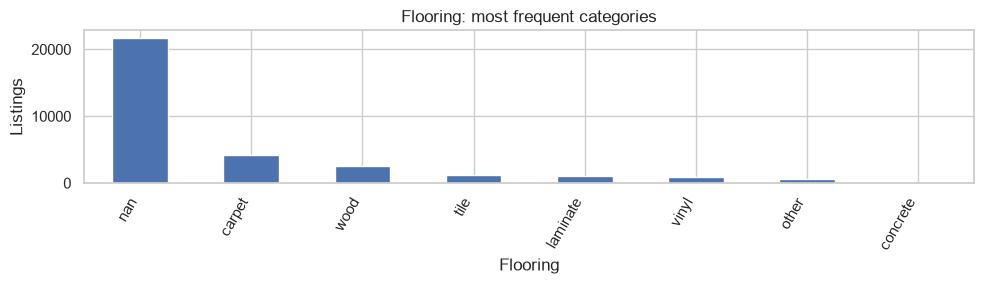


Roof: 17 observed categories (including missing)


,count,percent
Roof,,
NaN,26059,80.359566
asphalt,5168,15.936845
metal,528,1.628223
fiberglass,351,1.082398
other,91,0.280622
flat,43,0.132601
shingle,43,0.132601
tile,42,0.129518
cedar shake,25,0.077094


,count,percent
Rare category,,
other,91,0.280622
flat,43,0.132601
shingle,43,0.132601
tile,42,0.129518
cedar shake,25,0.077094
tar,20,0.061675
shake,19,0.058591
clay,17,0.052424
wood,12,0.037005


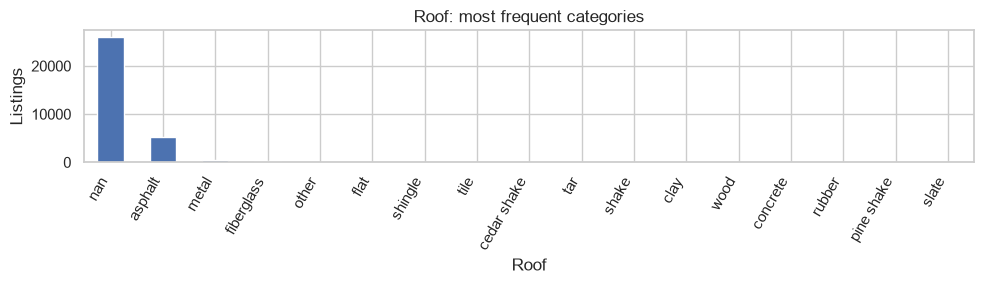


Waterfront: 2 observed categories (including missing)


,count,percent
Waterfront,,
No,32304,99.617614
Yes,124,0.382386


,count,percent
Rare category,,
Yes,124,0.382386


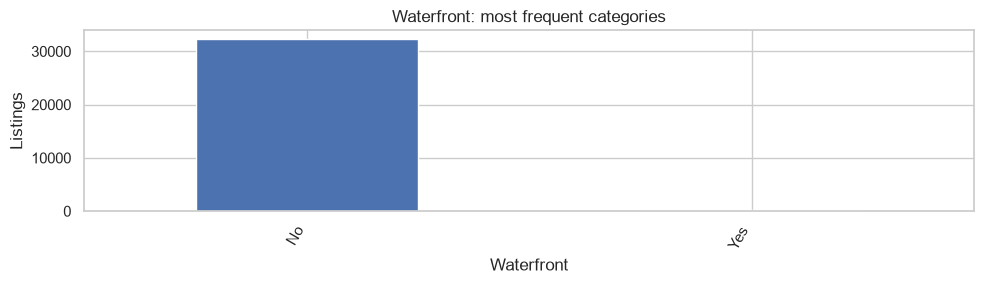


Sewer: 5 observed categories (including missing)


,count,percent
Sewer,,
none,20815,64.188356
municipal,8383,25.851116
septic,3100,9.559640
private,69,0.212779
alternative,61,0.188109


,count,percent
Rare category,,
private,69,0.212779
alternative,61,0.188109


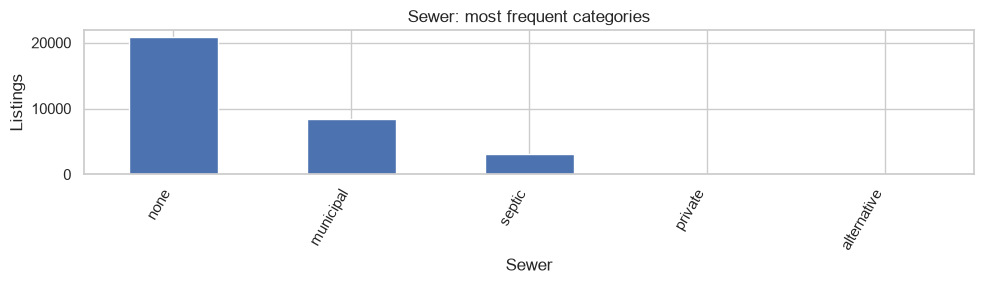


Pool: 2 observed categories (including missing)


,count,percent
Pool,,
No,32373,99.830393
Yes,55,0.169607


,count,percent
Rare category,,
Yes,55,0.169607


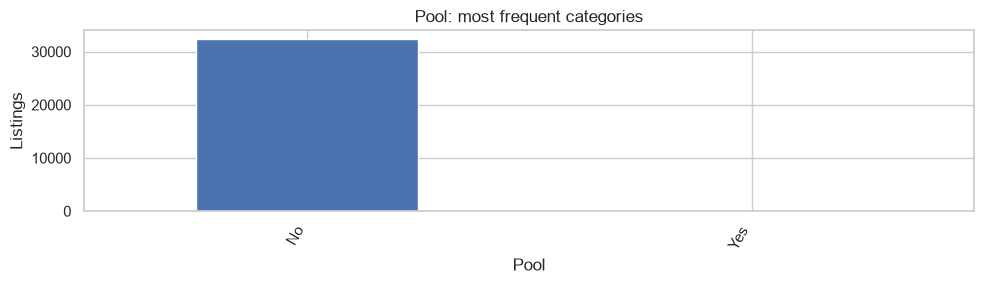


Garden: 2 observed categories (including missing)


,count,percent
Garden,,
No,31198,96.206982
Yes,1230,3.793018


,count,percent
Rare category,,


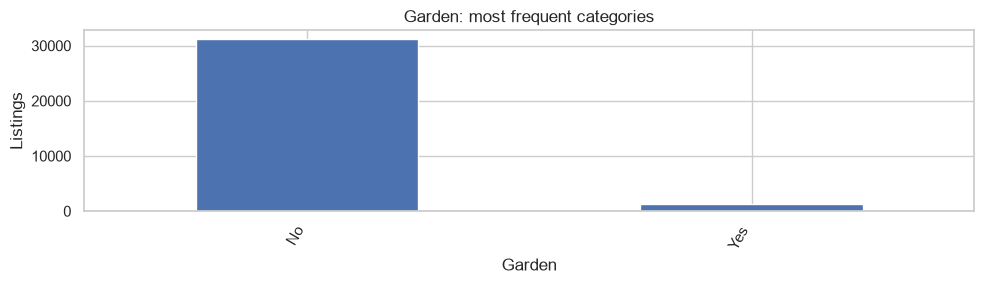


Balcony: 2 observed categories (including missing)


,count,percent
Balcony,,
No,30786,94.936475
Yes,1642,5.063525


,count,percent
Rare category,,


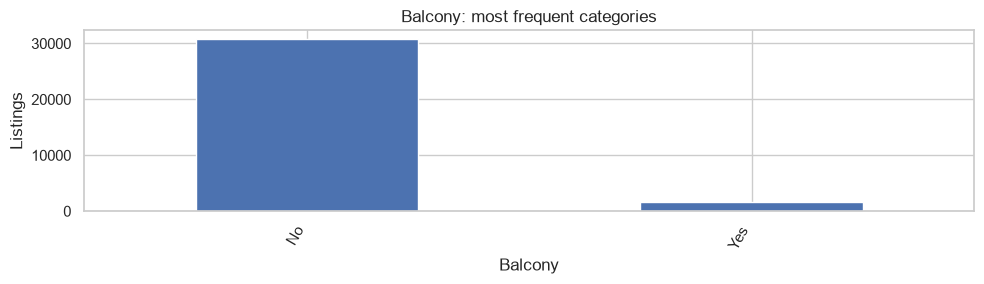

In [11]:
categorical_columns = df.select_dtypes(include=["object", "string"]).columns
RARE_SHARE = .01
for column in categorical_columns:
    counts = df[column].value_counts(dropna=False)
    table = pd.DataFrame({"count": counts, "percent": counts / len(df) * 100})
    print(f"\n{column}: {len(counts)} observed categories (including missing)")
    display(table)
    display(table.loc[table["percent"] < RARE_SHARE * 100].rename_axis("Rare category"))
    counts.head(20).plot.bar(figsize=(10, 3), ylabel="Listings", title=f"{column}: most frequent categories")
    plt.xticks(rotation=60, ha="right")
    plt.tight_layout()
    plt.show()

**Interpretation after running:**

- What pattern is visible, and how many listings support it?
- What uncertainty, missingness, or confounding could explain it?
- What should be investigated using development data or cross-validation?

_Write observations here; no findings are assumed in advance._

## 8. Potential outliers and unusual relationships

IQR fences are exploratory diagnostics, not cleaning rules. Report lower/upper fences and flagged counts, then inspect examples. The existing audit thresholds provide a second review view. Expensive, large, rural, and multi-family properties may be legitimate. Do not delete or correct any observation based on these summaries alone.

,column,lower,upper,flagged
0,Price,-848750.00,2587650.00,2671
1,Square Footage,-936.00,4160.00,1685
2,Bedrooms,-1.00,7.00,579
3,Bathrooms,0.50,4.50,2437
4,Acreage,-0.27,0.45,3974


area > 10000                    74
acreage > 100                   91
bedrooms >= 18                   8
bathrooms >= 17                  5
bathrooms > twice bedrooms     249
price >= 5m and area < 1000      4
Name: Review count, dtype: int64

Unique rows in this review view: 418


,City,Province,Latitude,Longitude,Price,Bedrooms,Bathrooms,Acreage,Property Type,Square Footage,Garage,Parking,Basement,Exterior,Fireplace,Heating,Flooring,Roof,Waterfront,Sewer,Pool,Garden,Balcony
99,Stoney Creek,ON,43.182012,-79.813035,2595000.0,0.0,0.0,0.00,Condo/Townhome,18270.0,No,No,NaN,NaN,No,NaN,NaN,NaN,No,municipal,No,No,No
162,Vancouver,BC,49.280027,-123.071359,2100000.0,0.0,3.0,0.09,Single Family,2689.0,Yes,Yes,NaN,NaN,No,radiant,NaN,NaN,No,none,No,No,No
233,Dawson Creek,BC,55.950268,-120.135834,765000.0,4.0,1.0,154.00,Single Family,2697.0,Yes,No,Finished,Vinyl,Yes,forced air,carpet,asphalt,No,none,No,No,No
250,Chilliwack,BC,49.105196,-121.965908,403900.0,0.0,1.0,0.00,Condo,465.0,Yes,No,NaN,NaN,No,heat pump,NaN,NaN,No,none,No,No,No
592,Fort St. John,BC,56.360515,-120.905007,1899900.0,4.0,3.0,156.17,Single Family,4576.0,No,Yes,Finished,Concrete,Yes,boiler,NaN,asphalt,No,none,No,No,No
606,Vancouver,BC,49.261606,-123.057762,594900.0,0.0,1.0,0.00,Condo,425.0,Yes,No,NaN,NaN,No,forced air,NaN,NaN,No,none,No,No,No
698,Kelowna,BC,49.826217,-119.496176,5699000.0,7.0,9.0,0.66,Single Family,10512.0,Yes,No,NaN,Concrete,Yes,forced air,NaN,tile,No,municipal,No,No,No
851,Victoria,BC,48.425979,-123.355757,329000.0,0.0,1.0,0.00,Condo,376.0,No,No,NaN,NaN,No,radiant,tile,NaN,No,municipal,No,No,No
856,Kelowna,BC,49.881554,-119.472054,317900.0,0.0,1.0,0.00,Single Family,313.0,No,Yes,NaN,NaN,No,heat pump,NaN,NaN,No,municipal,No,No,No
868,"Rural Northern Lights, County of",AB,56.296722,-117.305264,649000.0,5.0,4.0,136.00,Single Family,2000.0,Yes,No,Finished,NaN,Yes,boiler,carpet,asphalt,No,none,No,Yes,No


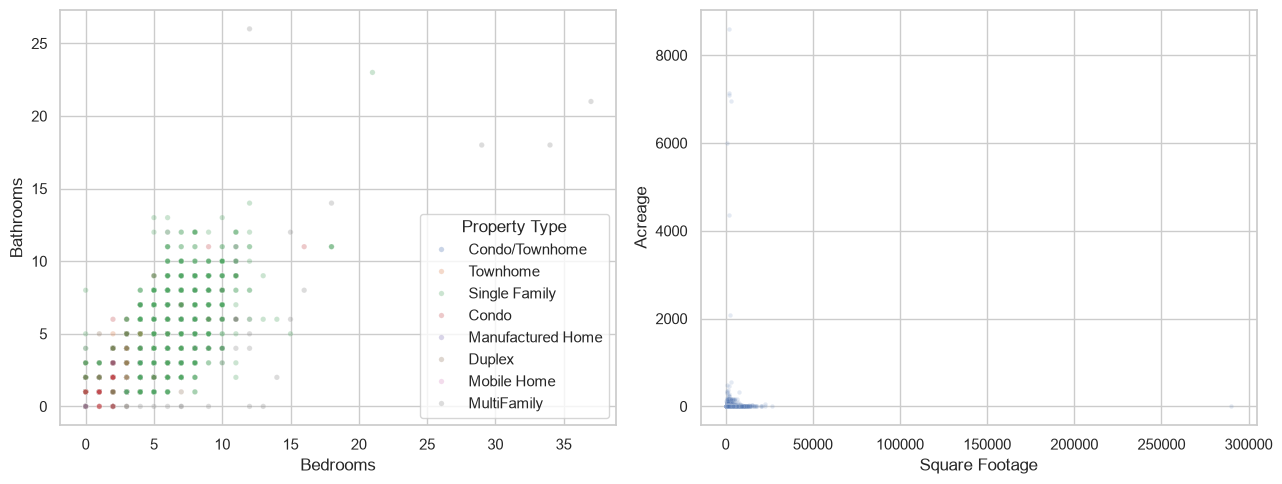

In [8]:
outlier_rows = []
for column in ["Price", *dimensions]:
    q1, q3 = df[column].quantile([.25, .75])
    iqr = q3 - q1
    lower, upper = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    outlier_rows.append({"column": column, "lower": lower, "upper": upper,
                         "flagged": int((df[column].lt(lower) | df[column].gt(upper)).sum())})
display(pd.DataFrame(outlier_rows))
review = pd.DataFrame({
    "area > 10000": df["Square Footage"].gt(10000),
    "acreage > 100": df["Acreage"].gt(100),
    "bedrooms >= 18": df["Bedrooms"].ge(18),
    "bathrooms >= 17": df["Bathrooms"].ge(17),
    "bathrooms > twice bedrooms": df["Bathrooms"].gt(2 * df["Bedrooms"]),
    "price >= 5m and area < 1000": df["Price"].ge(5_000_000) & df["Square Footage"].lt(1000),
})
display(review.sum().rename("Review count"))
print("Unique rows in this review view:", review.any(axis=1).sum())
display(df.loc[review.any(axis=1)].head(30))
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
sns.scatterplot(data=df, x="Bedrooms", y="Bathrooms", hue="Property Type", alpha=.3, s=15, ax=axes[0])
sns.scatterplot(data=df, x="Square Footage", y="Acreage", alpha=.15, s=10, ax=axes[1])
plt.tight_layout()
plt.show()

**Interpretation after running:**

- What pattern is visible, and how many listings support it?
- What uncertainty, missingness, or confounding could explain it?
- What should be investigated using development data or cross-validation?

_Write observations here; no findings are assumed in advance._

## 9. Property mix, amenities, and geographic coverage

Within-province comparisons help reveal differences in property mix. Amenity tables show sample sizes alongside descriptive prices; missing values remain a separate group. Coordinate coverage reflects the listings available, not national housing coverage. No causal amenity premiums or inference-time Price-derived features are estimated.

Property Type,Condo,Condo/Townhome,Duplex,Manufactured Home,Mobile Home,MultiFamily,Single Family,Townhome
Province,,,,,,,,
AB,21.7,4.6,6.2,0.0,1.2,0.1,61.3,4.8
BC,40.1,4.6,2.5,0.9,0.0,0.4,42.9,8.5
MB,17.6,3.9,0.0,0.0,0.0,0.0,78.4,0.0
NB,3.2,0.3,0.0,0.0,0.0,0.3,96.2,0.0
NL,2.5,0.3,0.0,0.0,0.0,0.0,97.3,0.0
NS,7.1,0.6,0.0,0.0,0.0,0.0,92.3,0.0
NT,11.1,11.1,0.0,0.0,0.0,0.0,77.8,0.0
ON,28.6,2.5,0.0,0.0,0.0,4.0,64.9,0.0
PE,8.9,0.8,0.0,0.0,0.0,0.0,90.3,0.0


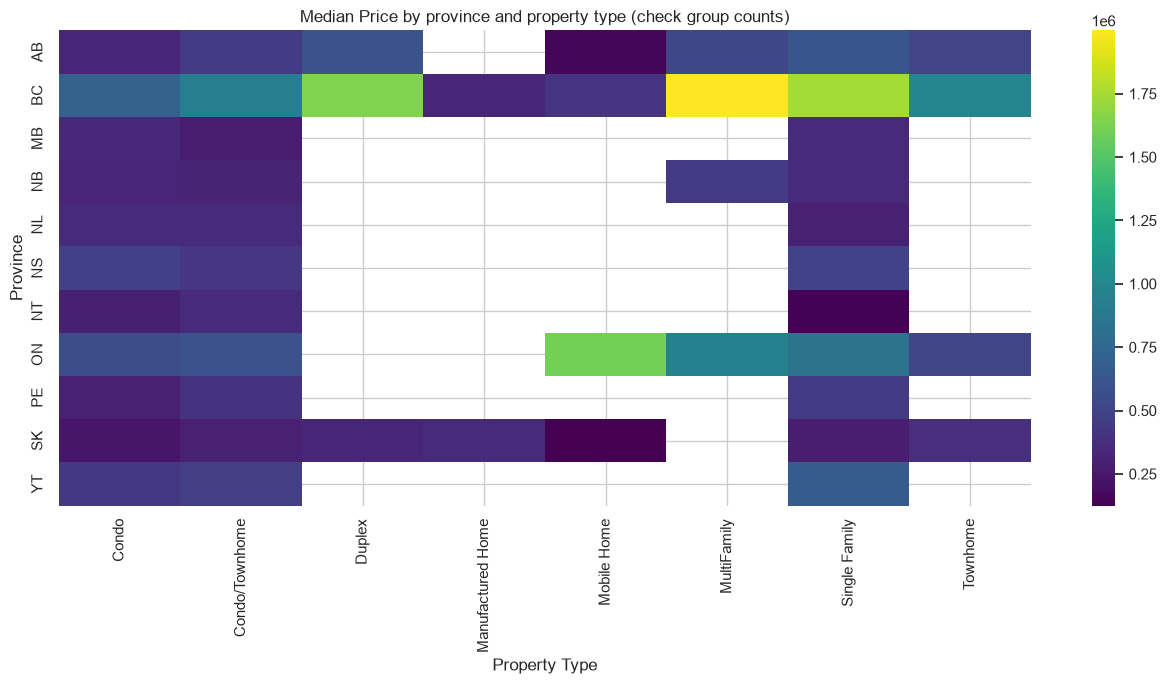

,count,median,mean
Garage,,,
No,9179,429000.0,6.992259e+05
Yes,23249,849900.0,1.306079e+06


,count,median,mean
Waterfront,,,
No,32304,724850.0,1.131345e+06
Yes,124,945000.0,1.905379e+06


,count,median,mean
Pool,,,
No,32373,724900.0,1.133346e+06
Yes,55,1095000.0,1.698343e+06


,count,median,mean
Garden,,,
No,31198,724900.0,1.140616e+06
Yes,1230,700000.0,9.742095e+05


,count,median,mean
Balcony,,,
No,30786,724999.0,1.141091e+06
Yes,1642,699900.0,1.007059e+06


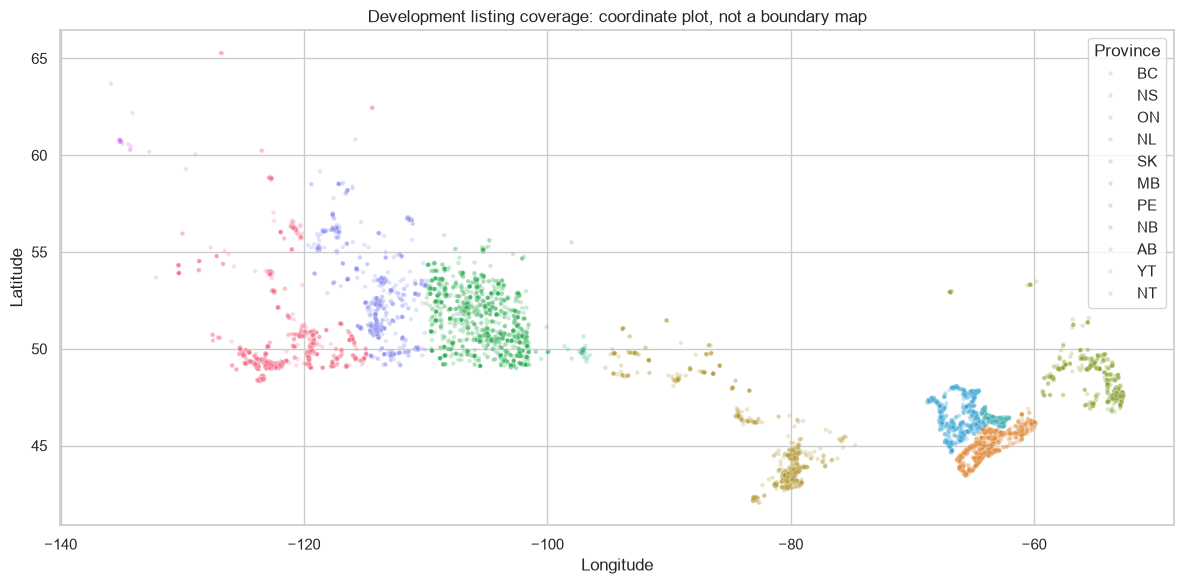

In [9]:
display(pd.crosstab(df["Province"], df["Property Type"], normalize="index").mul(100).round(1))
mix_prices = df.pivot_table(index="Province", columns="Property Type", values="Price", aggfunc="median")
plt.figure(figsize=(13, 7))
sns.heatmap(mix_prices, cmap="viridis", mask=mix_prices.isna())
plt.title("Median Price by province and property type (check group counts)")
plt.tight_layout()
plt.show()
for column in ["Garage", "Waterfront", "Pool", "Garden", "Balcony"]:
    display(df.groupby(column, dropna=False)["Price"].agg(["count", "median", "mean"]))
plt.figure(figsize=(12, 6))
sns.scatterplot(data=df, x="Longitude", y="Latitude", hue="Province", alpha=.25, s=10)
plt.title("Development listing coverage: coordinate plot, not a boundary map")
plt.tight_layout()
plt.show()

**Interpretation after running:**

- What pattern is visible, and how many listings support it?
- What uncertainty, missingness, or confounding could explain it?
- What should be investigated using development data or cross-validation?

_Write observations here; no findings are assumed in advance._

## 10. Integrity check and next steps

Confirm that EDA did not alter any loaded values. Record observations only after executing the notebook. Any later imputation, encoding, scaling, feature selection, or fitted transformations must be learned inside development training folds. Keep the test dataset untouched until the final evaluation plan and model are fixed. Do not build predictors from Price or Price per Square Footage.

In [10]:
pd.testing.assert_frame_equal(df, original)
print("PASS: development data unchanged; no test data loaded by this notebook.")

PASS: development data unchanged; no test data loaded by this notebook.


### Findings to complete after execution

- Main price distribution and skewness observations:
- Strongest associations, with sample sizes and caveats:
- Missingness patterns that need a preprocessing plan:
- Rare groups and limits of geographic coverage:
- Unusual listings requiring further review:
- Hypotheses to assess with development-only cross-validation:
- Evaluation limitations (related listings, spatial coverage, missing timestamps):